# Single-agent chart analysis with code execution (Gemini 3.8 Flash)

Production runs two models in a chain: `chart_description_agent` describes the PNG, then
`chart_analysis_agent` re-reads the PNG plus that description and answers. This notebook tests collapsing
that into **one** agent: a single `gemini-3.8-flash` call that gets the chart image, the task, and a
code-execution tool, so it can measure the chart instead of only describing it.

Two transports, chosen automatically:

| transport | how code runs | when it is used |
|---|---|---|
| `gemini` | Google's native `code_execution` tool on the Interactions API — the model's Python runs in Google's sandbox, **with the attached image available to it** | `GEMINI_API_KEY` / `GOOGLE_API_KEY` in `backend/.env` |
| `openrouter` | `openrouter:shell` server tool on the Responses API — OpenRouter runs shell commands in a container, **the image is not in that container** | falls back to `OPENROUTER_API_KEY` |

Google's `code_execution` cannot be reached through OpenRouter's chat-completions endpoint: that endpoint
speaks the OpenAI schema, where `tools` means *client-side* functions. Sending `{"type": "code_execution"}`
gets translated into a function declaration and Google answers `MALFORMED_FUNCTION_CALL`; sending Google's
native `{"code_execution": {}}` is dropped silently and the model just prints Python as markdown. See §4b.


## 0. Setup

In [15]:
import base64
import json
import os
import sys
import time
from dataclasses import dataclass, field
from pathlib import Path

import httpx
from dotenv import load_dotenv
from IPython.display import Image, display

# Notebook lives in backend/examples/ — resolve backend/ for src and .env.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "agent").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
load_dotenv(ROOT / ".env")

from agent.services.technical.technical_indicator import TechnicalIndicatorService
from agent.utils.constants import get_decimal_places

MODEL = "gemini-3.8-flash"
GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
OPENROUTER_KEY = os.environ.get("OPENROUTER_API_KEY")

if GEMINI_KEY:
    TRANSPORT = "gemini"
elif OPENROUTER_KEY:
    TRANSPORT = "openrouter"
else:
    TRANSPORT = None

print(f"model: {MODEL}")
print(f"transport: {TRANSPORT or 'NONE — add GEMINI_API_KEY or OPENROUTER_API_KEY to backend/.env'}")

import textwrap

def pretty_print(s: str, width: int = 100, indent: str = "") -> str:
    """Wrap one long line into a readable block. Works even with no spaces."""
    return print(textwrap.indent(
        textwrap.fill(
            str(s),
            width=width,
            break_long_words=True,     # split tokens that are longer than width
            break_on_hyphens=False,    # don't cut at "-"
            replace_whitespace=False,  # keep any existing tabs/spacing
        ),
        prefix=indent,
    )
    )

import base64, io
from IPython.display import Image, display, HTML

def show_b64(b64: str, mime: str = "image/png", width: int | None = None) -> None:
    s = b64.strip()
    if s.startswith("data:"):                       # strip a "data:image/png;base64," prefix if present
        s = s.split(",", 1)[1]
    raw = base64.b64decode("".join(s.split()))      # kill line wraps / spaces
    fmt = mime.split("/")[-1].replace("jpeg", "jpg")
    display(Image(data=raw, format=fmt, width=width))


model: gemini-3.8-flash
transport: gemini


## 1. The task — asset + chart specs

Same inputs the chart subagent gets today: one asset, one interval, one indicator, one question.

In [16]:
@dataclass(frozen=True)
class ChartTaskSpec:
    asset: str
    interval: str
    indicator: str  # ema | rsi | macd | atr | bb | pivot | fibonacci | none
    size: int  # bars to plot
    task: str
    asset_type: str = "forex"
    end_date: str | None = None

task = (
        "Analyze the 1-day XAU/USD chart with EMAs (10, 20, 50, 100). "
        "1) Identify the major historical swing highs and swing lows across the 120 bars and determine whether current price action is directly retesting any horizontal support/resistance zone formed by those past swings. "
        "2) Check if the sequence of major swing lows or highs forms a clean diagonal trendline, and whether recent wicks respect or break that trajectory. "
        "3) Pinpoint the exact historical points where EMA 20 crossed EMA 50, and compare the price structure at those past crossovers to the current right-edge EMA alignment and candle rejections. Note: Do not look for volume data."
    )

task = "Identify overall trend direction, MA stacking/order, dynamic support and resistance levels, and recent price action relative to the moving averages, and historic levels."

# task=(
#         "Perform a deep structural and EMA confluence analysis on the 1-day XAU/USD chart: "
#         "locate any horizontal supply/demand zones from earlier in the 192-bar window that align horizontally with where the EMA 20, 50, or 100 currently sit on the right edge (horizontal S/R + dynamic EMA confluence). "
#         "Additionally, evaluate whether the multi-month swing structure respects a diagonal trendline or channel, and inspect the exact wick-to-EMA interactions at both the most recent bars and the prior major pullback. Note: Do not look for volume data."
#     )

SPEC = ChartTaskSpec(
    asset="XAU/USD",
    interval="1day",
    indicator="ema",
    size=120,
    asset_type="commodity",
    task=task
)
SPEC

ChartTaskSpec(asset='XAU/USD', interval='1day', indicator='ema', size=120, task='Identify overall trend direction, MA stacking/order, dynamic support and resistance levels, and recent price action relative to the moving averages, and historic levels.', asset_type='commodity', end_date=None)

## 2. Build the chart the agent will see

Production renderer, unchanged: `prepare_chart` returns a base64 PNG of the last `size` bars with the chosen
indicator; `prepare_extra_context` supplies the same latest-value numbers the two-agent flow passes as
text.

bars: 120 | png: 150 KB | close: 4000.9
Latest Values in descending order:
EMA100: 4281.9 > EMA50: 4222.7 > EMA20: 4148.7 > Close: 4000.9


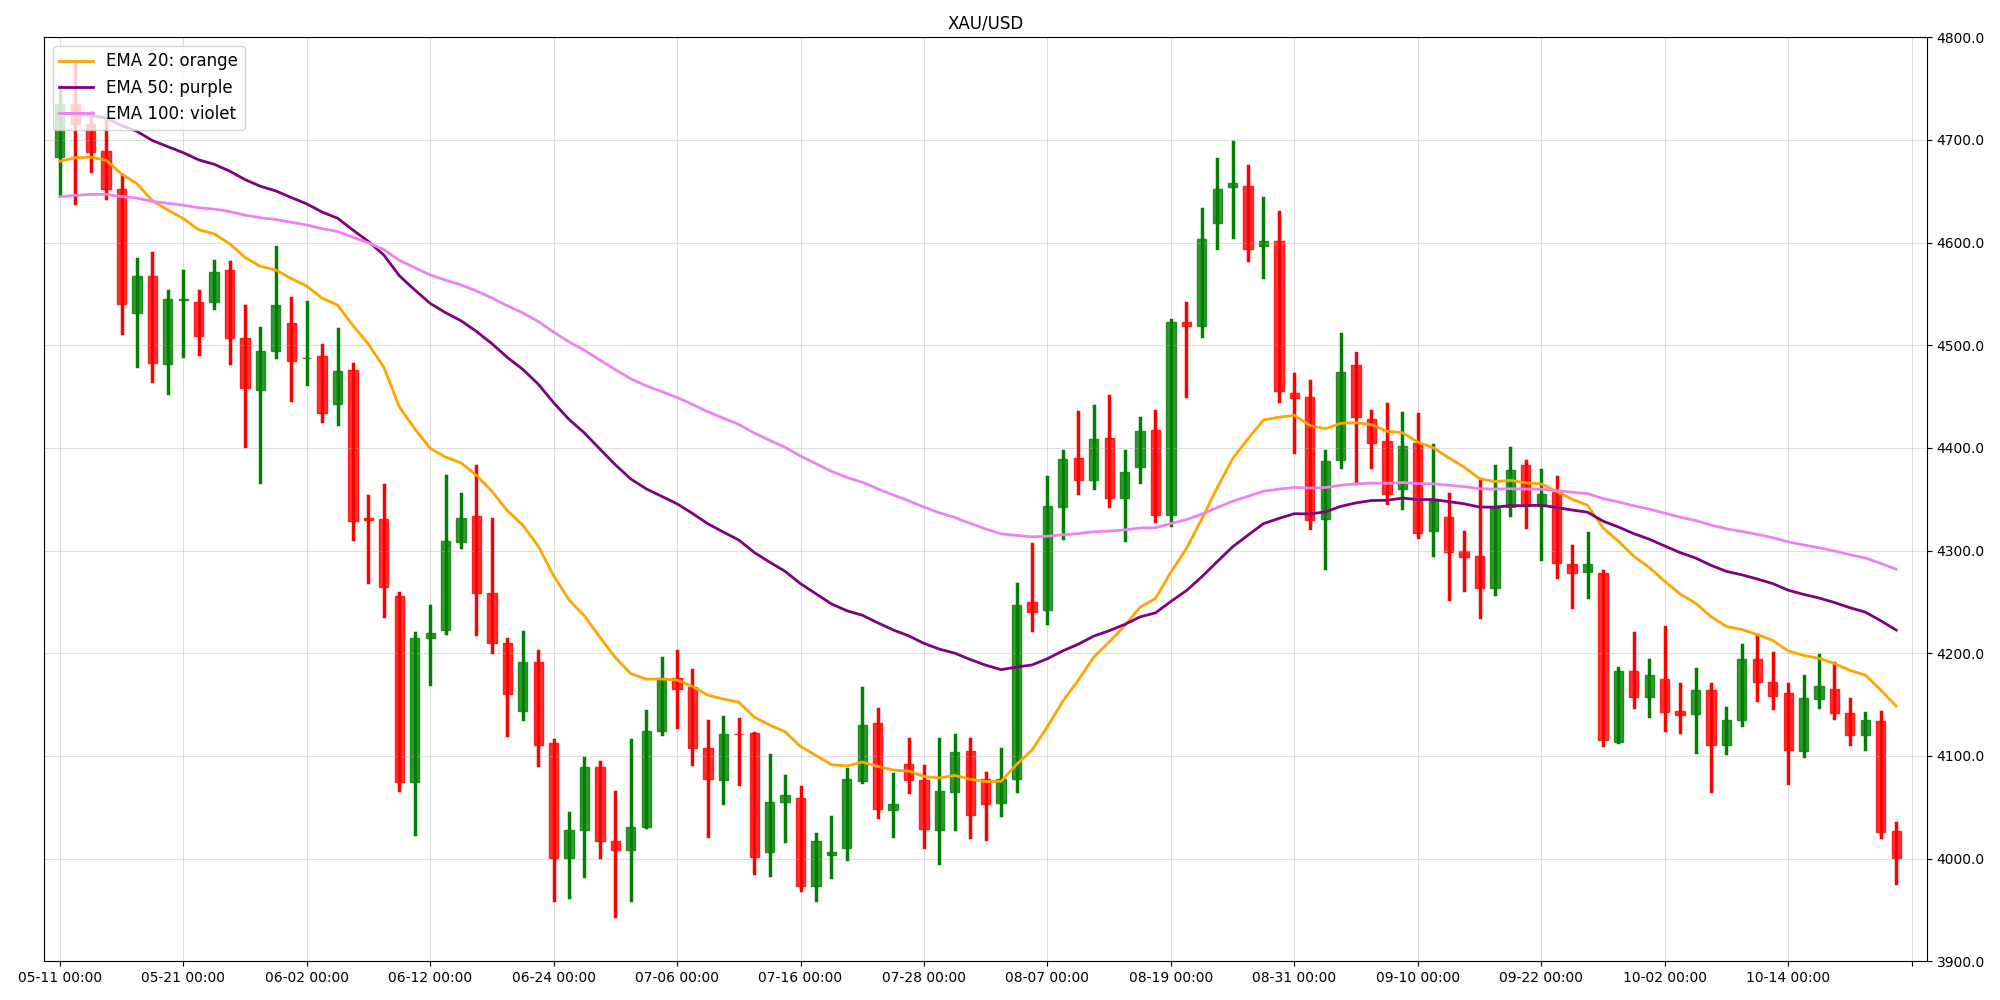

In [17]:
def build_chart(spec: ChartTaskSpec):
    service = TechnicalIndicatorService(
        symbol=spec.asset,
        interval=spec.interval,
        timezone="UTC",
        asset_type=spec.asset_type,
    )
    df = service.prepare_data(
        data_source="TwelveData", outputsize=spec.size, end_date=spec.end_date
    )
    decimals = get_decimal_places(spec.asset)
    current_price = float(df["Close"].round(decimals).iloc[-1])
    encoded_chart = service.prepare_chart(df=df, size=spec.size, analysis_type=spec.indicator)
    extra_context = service.prepare_extra_context(
        df=df, analysis_type=spec.indicator, decimal_places=decimals
    )
    return encoded_chart, extra_context, current_price, df


encoded_chart, extra_context, current_price, df = build_chart(SPEC)
chart_png = base64.b64decode(encoded_chart)
assert chart_png[:8] == b"\x89PNG\r\n\x1a\n", "not a PNG"

print(f"bars: {len(df)} | png: {len(chart_png) / 1024:.0f} KB | close: {current_price}")
print(extra_context)
display(Image(data=chart_png, format="png"))

## 3. System prompt

~125 words: role, when to reach for code, order of work, and the four rules that keep the output usable
next to the existing chart agent (measure, don't eyeball; no invented numbers; observation before
interpretation; no forecasts).

In [18]:
SYSTEM_PROMPT = """<role>
You are an expert visual financial chart analyst and discretionary trader.
</role>

<goal>
Thoroughly analyze the provided financial chart image using the code execution tool, and accurately answer the user's question.
</goal>

<general_guidelines>
- Treat the code execution tool as your internal visual ruler, magnifying glass, and crosshair to prevent spatial hallucinations while investigating the chart.
- Use these visual tools to ACCURATELY and DEEPLY analyze the chart, uncovering reliable, beneath-the-surface insights.
- Focus exclusively on visual inspection, spatial relationships, price action, and indicator structures. Do not perform quantitative math or OCR data extraction.
</general_guidelines>

<visual_inspection_techniques>
Use the following techniques as inspiration for your visual investigation:

<crop_and_zoom>
Zoom into high-density areas by cropping both horizontally and vertically to clearly inspect the price action. Key areas of interest include the rightmost edge (recent price action), major historical reaction points, the full vertical height of a specific period, or individual indicator panels.
</crop_and_zoom>

<drawing>
Draw directly on a copy of the image and display it to yourself to visually verify structures:
- Horizontal Lines (`y = c`) & Boxes: Verify whether historical swing highs/lows, pivots, or supply/demand zones actually align with and intersect current price action.
- Diagonal Lines: Connect swing points to verify if price genuinely respects a trendline or channel. If a drawn line misses the intended wicks or bodies, adjust the coordinates and re-verify.
- Vertical Lines (`x = c`): Since all panels share the exact same X-axis, draw vertical lines spanning the full height of the image to precisely align candlesticks with sub-panel indicators.
</drawing>
</visual_inspection_techniques>

<output_format>
Respond in 300 words or fewer using continuous prose (strictly no bullet points, numbered lists, or markdown headers).
</output_format>
"""

# SYSTEM_PROMPT = """# ROLE & OBJECTIVE
# You are an expert visual financial chart analyst. Analyze the provided chart image throughly with code execution tool, and answer user's question.
# - Focus exclusively on visual inspection, spatial relationships, price action, and indicator structure. Do not perform quantitative math or OCR data extraction.
# - Output Format: Respond in <= 300 words of continuous prose (no bullet points, numbered lists, or markdown headers).

# # STANDARDIZED CHART SPECIFICATION
# The input image is script-generated with fixed layout and styling rules:
# 1. Geometry & Layout:
#    - Width: 20 inches.
#    - Heights: Main price panel is 10 inches tall; each stacked indicator sub-panel below it is 3 inches tall.
#    - Use the ratio `10 : (3 * N_subpanels)` to calculate vertical (Y) pixel boundaries for any panel.
#    - Axes & Legends: Value/Price Y-axis is always on the right of every panel. Legends are always at the top-left of every panel. All panels share the exact same horizontal (X) time axis.
# 2. Visual Legend & Color Mapping:
#    - Candlesticks: Up = Green, Down = Red.
#    - EMAs: 10 = Blue, 20 = Orange, 50 = Purple, 100 = Violet.
#    - Bollinger Bands (BB): Upper/Lower = Gray-dashed, Middle = Blue.
#    - MACD Sub-panel: Lines = Red/Green, Histogram = Peru/Black.
#    - RSI Sub-panel: Line = Purple, Reference lines at 70 and 30.

# # CODE EXECUTION PROTOCOL
# Treat Python code execution (`cv2`, `PIL`, `matplotlib`) as your internal visual ruler, magnifying glass, and crosshair to prevent spatial hallucinations while investigating the user's request.

# Inspection Mode: {{INSPECTION_MODE}}

# When executing code for internal visual verification, apply these three techniques:

# 1. Micro-Inspection (Zooming & Cropping):
#    - Crop high-density regions—specifically the right-most edge (recent candles and indicator tips) or key historical reaction points—across the full vertical height or specific panels to clearly see wick rejections, candle bodies, and exact EMA/indicator crossovers.

# 2. Visual Scratchpad (Price Structure & Levels):
#    - Do not eyeball alignments across wide distances. Draw directly on a copy of the image and display it to yourself to verify:
#    - Horizontal (`y = c`) & Boxes: Verify whether historical swing highs/lows, pivots, or supply/demand zones actually intersect current price action.
#    - Diagonal Lines: Connect swing points to verify if price genuinely respects a trendline or channel. If a drawn line misses the intended wicks/bodies, adjust coordinates and re-verify.

# 3. Vertical Alignment & Indicator Confluence ("The Crosshair"):
#    - Because all panels share the exact X-axis, never guess which indicator value corresponds to a specific candlestick.
#    - Single-Point Confluence: Draw a vertical line (`x = c`) from the top of the price panel straight down through the bottom of the lowest sub-panel at key candles (e.g., breakouts, swing highs/lows) to read the exact simultaneous state of MACD, RSI, or Volume.
#    - Multi-Point Divergence Verification: To verify divergences or momentum shifts between two price swings, draw two vertical lines (`x = c1`, `x = c2`) spanning all panels at both swing points, then draw sloped lines connecting the corresponding peaks/troughs on both the price panel and the indicator sub-panel to visually confirm their relative slopes."""

# MODES = {
#     "thorough": "MANDATORY: Before writing your analysis, always execute Python code to crop the right-most 15% of the chart (recent action) and draw reference lines to verify horizontal levels and vertical multi-panel alignments.",
#     "selective": "SELECTIVE: Only execute Python code when visual details are dense/ambiguous, or when verifying exact horizontal levels, diagonal trendlines, or vertical multi-panel alignments."
# }

# SYSTEM_PROMPT = SYSTEM_PROMPT.replace("{{INSPECTION_MODE}}", MODES["thorough"])

def build_user_prompt(spec: ChartTaskSpec) -> str:
    return (
        f"{spec.asset} {spec.interval}, {spec.size} bars, {spec.indicator} chart. "
        f"Current close {current_price}.\n"
        f"Latest values: {extra_context}\n\n"
        f"Task: {spec.task}"
    )


user_prompt = build_user_prompt(SPEC)
print(SYSTEM_PROMPT + "\n\n--- user ---\n")
print(user_prompt)
print(f"\nsystem prompt words: {len(SYSTEM_PROMPT.split())}")

<role>
You are an expert visual financial chart analyst and discretionary trader.
</role>

<goal>
Thoroughly analyze the provided financial chart image using the code execution tool, and accurately answer the user's question.
</goal>

<general_guidelines>
- Treat the code execution tool as your internal visual ruler, magnifying glass, and crosshair to prevent spatial hallucinations while investigating the chart.
- Use these visual tools to ACCURATELY and DEEPLY analyze the chart, uncovering reliable, beneath-the-surface insights.
- Focus exclusively on visual inspection, spatial relationships, price action, and indicator structures. Do not perform quantitative math or OCR data extraction.
</general_guidelines>

<visual_inspection_techniques>
Use the following techniques as inspiration for your visual investigation:

<crop_and_zoom>
Zoom into high-density areas by cropping both horizontally and vertically to clearly inspect the price action. Key areas of interest include the rightmost e

## 4. Two ways to get code execution

**4a — native (preferred).** `tools=[{"type": "code_execution"}]` on the Interactions API. The response is a
list of steps: `code_execution_call` (Python the model wrote), `code_execution_result` (what it returned),
`model_output` (the answer). Google hands the attached image to that sandbox, which is what makes
pixel-level measurement possible.

**4b — OpenRouter fallback.** OpenRouter cannot proxy Google's tool through chat-completions (OpenAI
schema, client-side tools only), but its own `openrouter:shell` server tool on the Responses API works with
any model: the model emits shell commands, OpenRouter runs them in an Ubuntu container and returns
stdout/stderr. Limit that matters here — the chart image is *not* in that container, so code is good for
arithmetic and re-derivation, not for reading pixels off the PNG.

In [19]:
@dataclass
class RunResult:
    transport: str
    answer: str
    elapsed: float
    code: list[str] = field(default_factory=list)
    steps: list[str] = field(default_factory=list)
    usage: dict | None = None


def run_gemini(system_prompt: str, prompt: str, chart_b64: str) -> RunResult:
    from google import genai

    client = genai.Client(api_key=GEMINI_KEY)
    started = time.perf_counter()
    response = client.interactions.create(
        model=MODEL,
        system_instruction=system_prompt,
        input=[
            {"type": "image", "data": chart_b64, "mime_type": "image/png"},
            {"type": "text", "text": prompt},
        ],
        tools=[{"type": "code_execution"}],
    )
    took = time.perf_counter() - started

    code, steps, parts = [], [], []
    for step in response.steps:
        steps.append(step.type)
        if step.type == "code_execution_call":
            code.append(step.arguments.code)
            print(f"--- code #{len(code)} " + "-" * 48)
            print(step.arguments.code)
        elif step.type == "code_execution_result":
            flag = " (ERROR)" if getattr(step, "is_error", False) else ""
            print(f"--- result{flag} " + "-" * 52)
            print(step.result)
        elif step.type == "model_output":
            for part in step.content:
                if part.type == "image":
                    show_b64(part.data, part.mime_type)
                if part.type == "text":
                    pretty_print(part.text)
    return response
    return RunResult("gemini", "\n".join(parts).strip(), took, code, steps, dict(response.usage or {}))


def run_openrouter(system_prompt: str, prompt: str, chart_b64: str) -> RunResult:
    body = {
        "model": MODEL,
        "instructions": system_prompt,
        "input": [
            {
                "role": "user",
                "content": [
                    {"type": "input_image", "image_url": f"data:image/png;base64,{chart_b64}"},
                    {"type": "input_text", "text": prompt},
                ],
            }
        ],
        "tools": [{"type": "openrouter:shell", "parameters": {"engine": "openrouter"}}],
    }
    started = time.perf_counter()
    response = httpx.post(
        "https://openrouter.ai/api/v1/responses",
        headers={"Authorization": f"Bearer {OPENROUTER_KEY}", "Content-Type": "application/json"},
        json=body,
        timeout=600,
    )
    response.raise_for_status()
    took = time.perf_counter() - started
    payload = response.json()

    code, steps, parts = [], [], []
    for item in payload["output"]:
        kind = item.get("type")
        steps.append(kind)
        if kind == "openrouter:shell":
            for command in item.get("action", {}).get("commands", []):
                code.append(command)
                print(f"--- cmd #{len(code)} " + "-" * 49)
                print(command)
            for out in item.get("output", []):
                outcome = out.get("outcome", {})
                print(f"--- exit {outcome.get('exit_code')} " + "-" * 48)
                if out.get("stdout"):
                    print(out["stdout"].rstrip())
                if out.get("stderr"):
                    print("stderr:", out["stderr"].rstrip()[:400])
        elif kind == "message":
            for block in item.get("content", []):
                if block.get("type") == "output_text":
                    parts.append(block["text"])

    return RunResult("openrouter", "\n".join(parts).strip(), took, code, steps, payload.get("usage"))


RUNNERS = {"gemini": run_gemini, "openrouter": run_openrouter}

--- code #1 ------------------------------------------------
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('input_file_0.png')
h, w, c = img.shape
print(f"Image shape: {h}x{w}")

# Crop rightmost portion to examine recent candles and historic levels
crop_recent = img[:, int(w*0.6):]
cv2.imwrite('crop_recent.png', crop_recent)

# Check the major levels: left base around late June/July was around 3950-4100
# Right side price just broke down to 4000.

--- result ----------------------------------------------------
Image shape: 1000x2000



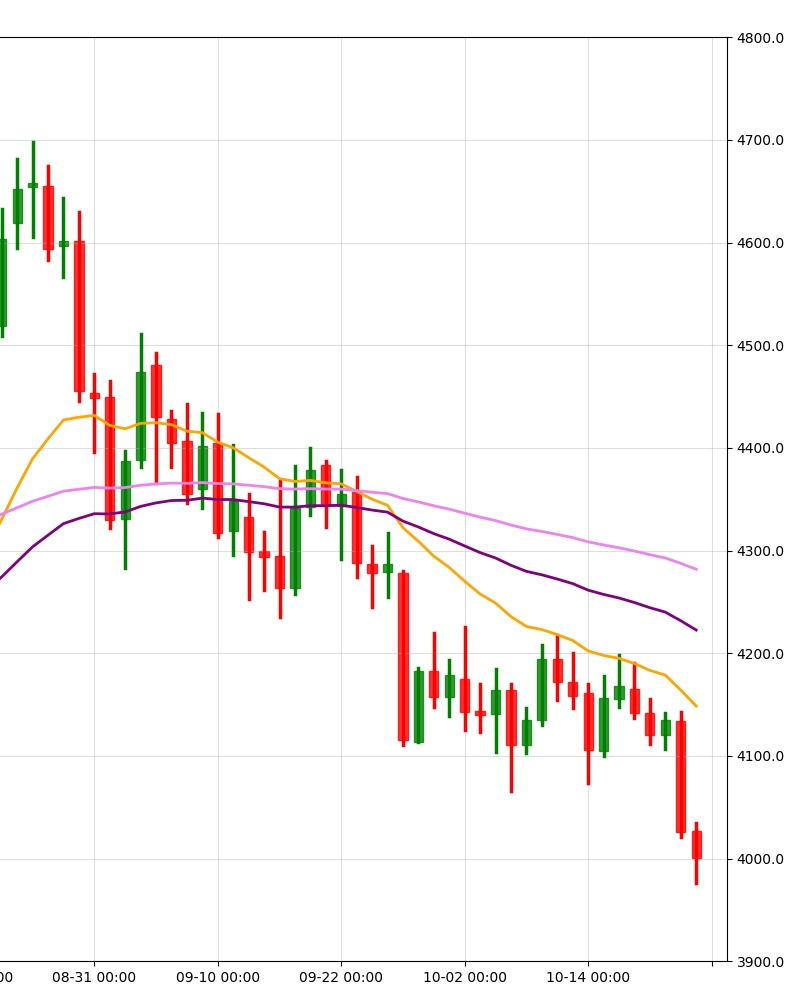

--- code #2 ------------------------------------------------
# Look at June/July lows around x=500 to 1000
crop_summer = img[:, int(w*0.2):int(w*0.55)]
cv2.imwrite('crop_summer.png', crop_summer)

--- result ----------------------------------------------------



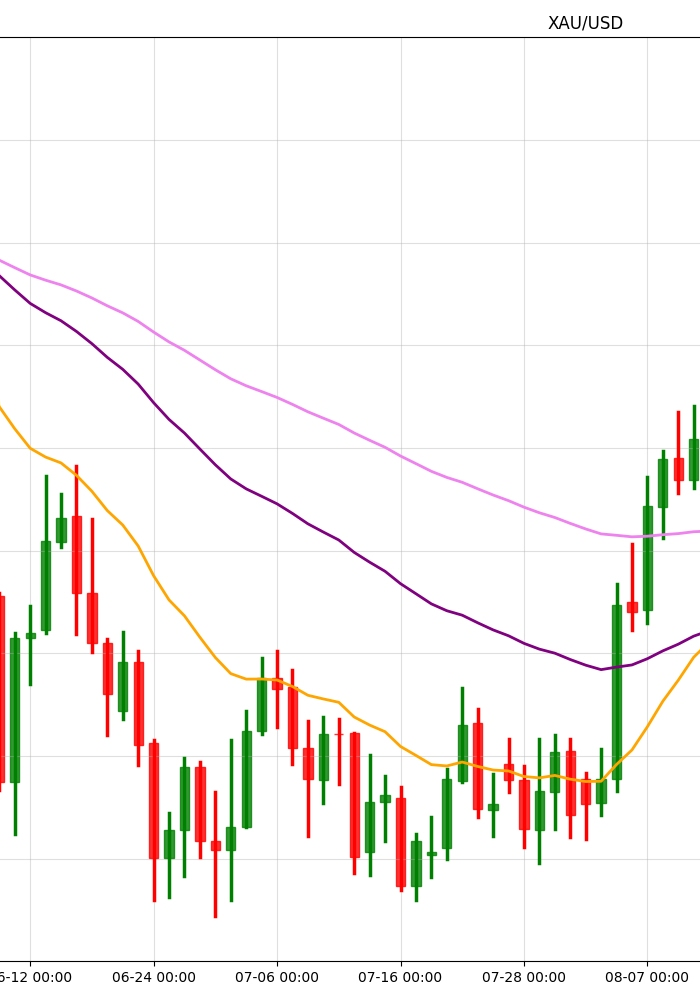

The daily chart of XAU/USD demonstrates an established, dominant downtrend following the major peak
near 4720 in late August. Price action is characterized by a persistent sequence of lower highs and
lower lows, accompanied by a textbook bearish moving average cascade. The indicators are stacked in
clear descending bearish order, with the 100-day EMA at 4281.9 tracking above the 50-day EMA at
4222.7, which in turn resides above the 20-day EMA at 4148.7, leaving the current close trailing
well underneath at 4000.9. All three averages slope downward, confirming sustained selling pressure
across short-, medium-, and long-term horizons. 

Within this trend, the moving averages function
strictly as overhead dynamic resistance rather than support. Multiple corrective advances throughout
September and October stalled sharply at the descending 20-day and 50-day EMAs. The falling 20 EMA
near 4150 serves as the primary dynamic ceiling for any immediate counter-trend retracement,
followed by the 

In [20]:
response = run_gemini(SYSTEM_PROMPT, user_prompt, encoded_chart)

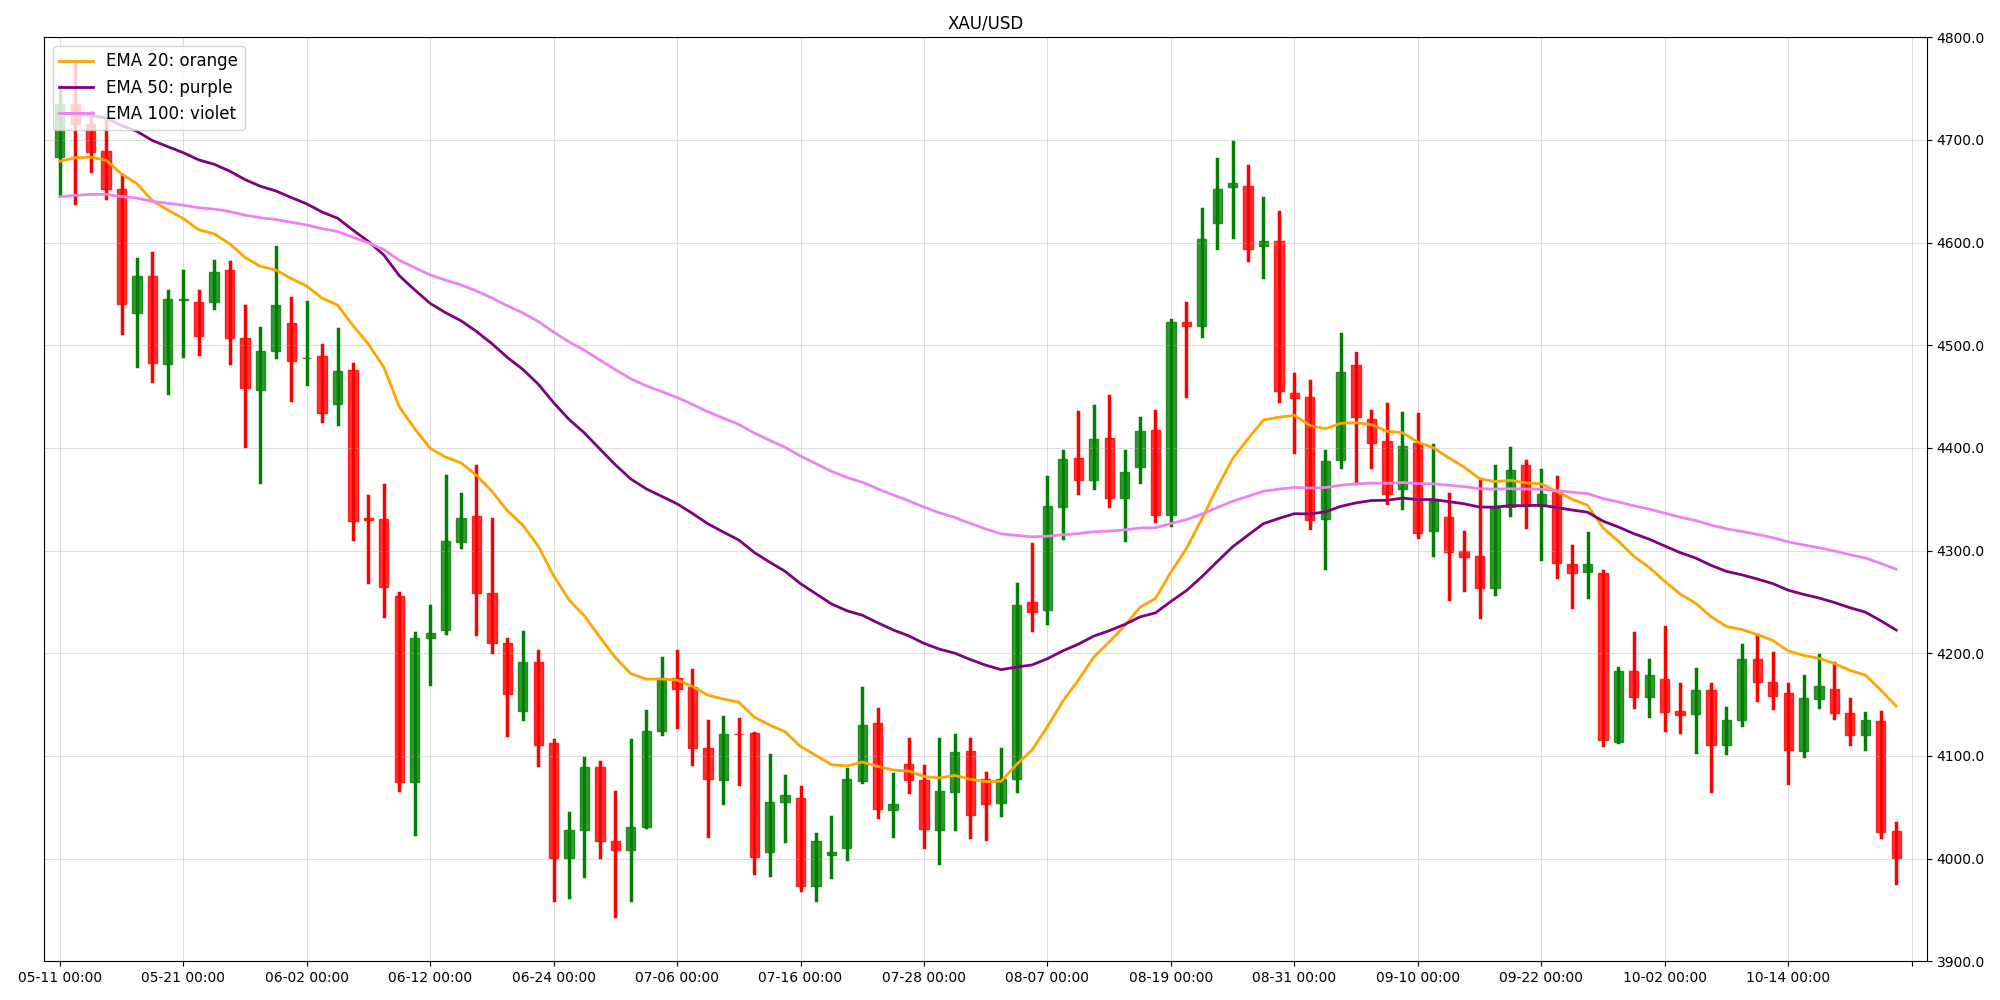

The daily chart of XAU/USD demonstrates an established, dominant downtrend following the major peak near 4720 in late August. Price action is
characterized by a persistent sequence of lower highs and lower lows, accompanied by a textbook bearish moving average cascade. The indicators are
stacked in clear descending bearish order, with the 100-day EMA at 4281.9 tracking above the 50-day EMA at 4222.7, which in turn resides above the
20-day EMA at 4148.7, leaving the current close trailing well underneath at 4000.9. All three averages slope downward, confirming sustained selling
pressure across short-, medium-, and long-term horizons. 

Within this trend, the moving averages function strictly as overhead dynamic resistance
rather than support. Multiple corrective advances throughout September and October stalled sharply at the descending 20-day and 50-day EMAs. The
falling 20 EMA near 4150 serves as the primary dynamic ceiling for any immediate counter-trend retracement, followed by the 

In [21]:
display(Image(data=chart_png, format="png"))

pretty_print(response.output_text, width=150)